<a href="https://colab.research.google.com/github/arambhaghimirecs24-stack/AI/blob/main/1BF24CS062_Week10_SimulatedAnnealing_8_Queens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
import random
import math
import matplotlib.pyplot as plt
import numpy as np

def get_conflicts(state):
    """Calculate the number of mutual threats (conflicts) on the board."""
    conflicts = 0
    n = len(state)
    for i in range(n):
        for j in range(i + 1, n):
            # Same row
            if state[i] == state[j]:
                conflicts += 1
            # Same diagonal
            elif abs(state[i] - state[j]) == abs(i - j):
                conflicts += 1
    return conflicts

def get_neighbor(state):
    """Generate a neighbor state by randomly moving one queen to another row in its column."""
    neighbor = list(state)
    col = random.randint(0, len(state) - 1)
    row = random.randint(0, len(state) - 1)
    while row == state[col]:
        row = random.randint(0, len(state) - 1)
    neighbor[col] = row
    return neighbor

In [20]:
def simulated_annealing(initial_state, initial_temp=10.0, cooling_rate=0.99, max_iterations=5000):
    """Solve 8-Queens using Simulated Annealing."""
    current_state = list(initial_state)
    current_energy = get_conflicts(current_state)

    temp = initial_temp
    history = [current_energy]

    for iteration in range(max_iterations):
        if current_energy == 0:
            break

        neighbor = get_neighbor(current_state)
        neighbor_energy = get_conflicts(neighbor)

        delta_energy = neighbor_energy - current_energy

        # If the neighbor is better, accept it.
        # If it's worse, accept it with a probability determined by the Boltzmann distribution.
        if delta_energy < 0:
            current_state = neighbor
            current_energy = neighbor_energy
        else:
            acceptance_probability = math.exp(-delta_energy / temp)
            if random.random() < acceptance_probability:
                current_state = neighbor
                current_energy = neighbor_energy

        temp *= cooling_rate
        history.append(current_energy)

    return current_state, current_energy, history

In [21]:
# Run Simulated Annealing
random.seed(42)
initial_state = [random.randint(0, 7) for _ in range(8)]

solution, final_conflicts, history = simulated_annealing(initial_state)

print(f"Initial State: {initial_state} (Conflicts: {get_conflicts(initial_state)})")
print(f"Solution State: {solution} (Conflicts: {final_conflicts})")

Initial State: [1, 0, 4, 3, 3, 2, 1, 1] (Conflicts: 10)
Solution State: [3, 5, 7, 2, 0, 6, 4, 1] (Conflicts: 0)


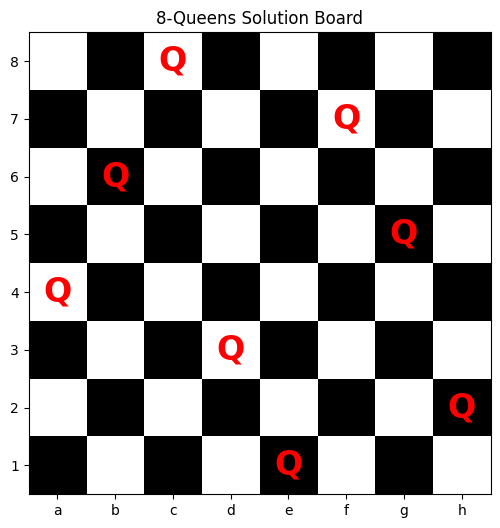

In [22]:
def plot_board(state):
    """Visualize the chessboard and queen placements."""
    n = len(state)
    board = np.zeros((n, n))
    board[1::2, ::2] = 0.6
    board[::2, 1::2] = 0.6

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(board, cmap='gray', origin='lower')

    for col, row in enumerate(state):
        ax.text(col, row, '👑', fontsize=30, ha='center', va='center', color='red')

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels([chr(97 + i) for i in range(n)])
    ax.set_yticklabels(range(1, n + 1))
    plt.title("8-Queens Solution Board")
    plt.grid(False)
    plt.show()

# Plot the board representation if a solution was found
plot_board(solution)